<a href="https://colab.research.google.com/github/Mayaracar2/Datascience_Woman/blob/main/Projeto_Women.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
ds = pd.read_csv('women_in_stem.csv',sep = ',')
print(ds)
#print(ds.columns) # visualizando as colunas

       Country  Year  Female Enrollment (%)  Female Graduation Rate (%)  \
0        China  2018                   20.4                        43.2   
1        China  2005                   35.6                        29.3   
2        China  2005                   53.7                        32.4   
3      Germany  2007                   65.0                        63.6   
4       Canada  2010                   54.4                        28.8   
..         ...   ...                    ...                         ...   
495  Australia  2016                   37.2                        50.1   
496      India  2010                   59.1                        61.2   
497    Germany  2010                   34.7                        34.2   
498  Australia  2011                   61.2                        39.9   
499      India  2008                   27.6                        49.1   

          STEM Fields  Gender Gap Index  
0         Engineering              0.52  
1         Mathe

1- Quais países apresentam o maior percentual médio de matrícula feminina em cada área STEM?



Países com maior matrícula feminina média por área:
     STEM Fields   Country  Female Enrollment (%)
         Biology     India                  45.88
Computer Science       USA                  47.72
     Engineering Australia                  50.53
     Mathematics       USA                  50.57


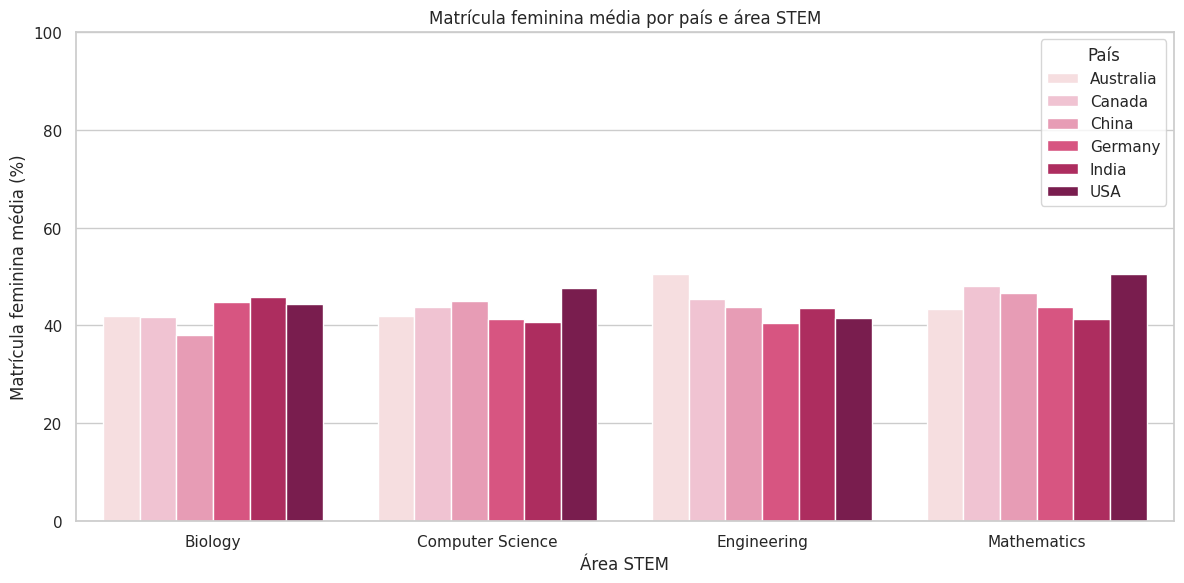

In [20]:
#Calculando a média de matrícula feminina por área e país
medias = (ds.groupby(["STEM Fields", "Country"])["Female Enrollment (%)"].mean().reset_index()) #O reset organiza uma tabela com três colunas

#Encontrar a maior média por cada área
maior_media = medias.groupby("STEM Fields")["Female Enrollment (%)"].transform("max")

#Seleciona os países com a maior média, incluindo possíveis empates
vencedores = medias[medias["Female Enrollment (%)"] == maior_media]

print("Países com maior matrícula feminina média por área:")
print(vencedores.round(2).to_string(index=False))

#Define o estilo com linhas de grade
sns.set_style("whitegrid")

#Define o tamanho das fontes
sns.set_context("notebook")

#Define o tamanho da figura
plt.figure(figsize=(12, 6))

#Cria o gráfico de barras agrupadas
sns.barplot(
    data=medias,
    x="STEM Fields",
    y="Female Enrollment (%)",
    hue="Country",
    palette=[
         "#FADADD",  # Rosa bem claro
        "#F8BBD0",   # Rosa claro
        "#F48FB1",   # Rosa médio
        "#EC407A",   # Rosa intenso
        "#C2185B",   # Rosa escuro
        "#880E4F"    # Rosa bem escuro
    ]
)

#Define o título e os nomes dos eixos
plt.title("Matrícula feminina média por país e área STEM")
plt.xlabel("Área STEM")
plt.ylabel("Matrícula feminina média (%)")

#Define a escala de percentual
plt.ylim(0, 100)

#Exibe a legenda dos países
plt.legend(title="País")

#Ajusta os espaços e exibe o gráfico
plt.tight_layout()
plt.show()



2- Como o índice de igualdade de gênero se distribui em cada área STEM?

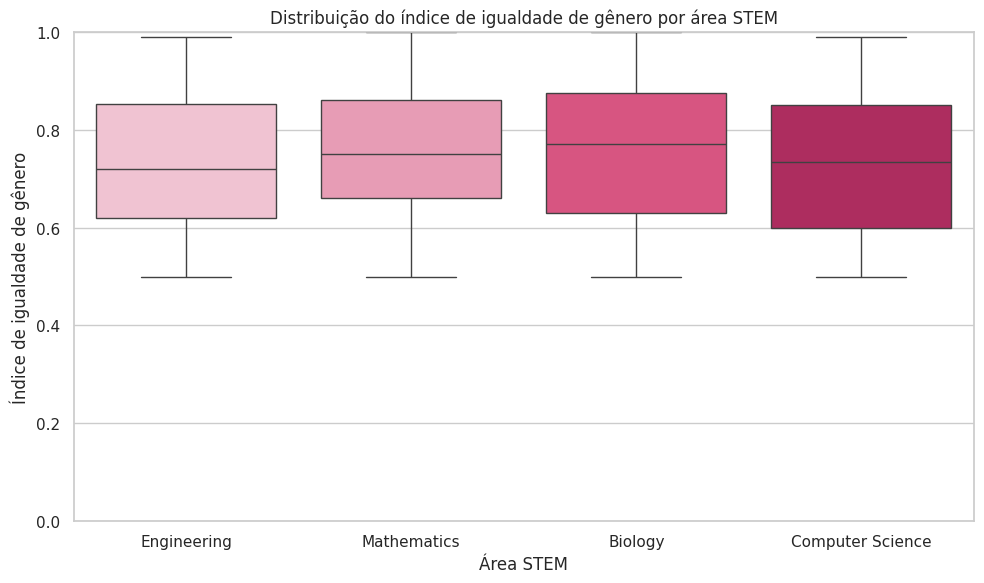

In [21]:
#Define o estilo e o tamanho das fontes
sns.set_style("whitegrid")
sns.set_context("notebook")

#Define o tamanho da figura
plt.figure(figsize=(10, 6))

#Compara a distribuição do índice entre as áreas STEM
sns.boxplot(
    data=ds,
    x="STEM Fields",
    y="Gender Gap Index",
    hue="STEM Fields",
    dodge=False,
    palette=[
        "#F8BBD0",  # Rosa claro
        "#F48FB1",  # Rosa médio
        "#EC407A",  # Rosa intenso
        "#C2185B"   # Rosa escuro
    ]
)

plt.title("Distribuição do índice de igualdade de gênero por área STEM")
plt.xlabel("Área STEM")
plt.ylabel("Índice de igualdade de gênero")
plt.ylim(0, 1)

#Remove a legenda, pois as áreas já aparecem no eixo horizontal
plt.legend([], [], frameon=False)

plt.tight_layout()
plt.show()

3-  Quais combinações de país e área apresentam os menores índices médios de igualdade de gênero?

Combinações ordenadas do menor índice médio para o maior:
  Country      STEM Fields  Gender Gap Index
      USA Computer Science             0.674
    India Computer Science             0.685
    China          Biology             0.694
   Canada      Engineering             0.712
Australia Computer Science             0.712
      USA          Biology             0.725
   Canada      Mathematics             0.729
    China      Engineering             0.731
      USA      Mathematics             0.733
      USA      Engineering             0.740
Australia      Engineering             0.742
  Germany      Engineering             0.743
  Germany          Biology             0.759
    India      Engineering             0.760
  Germany Computer Science             0.762
Australia      Mathematics             0.764
    India          Biology             0.765
    India      Mathematics             0.766
    China Computer Science             0.774
    China      Mathematics             0.7

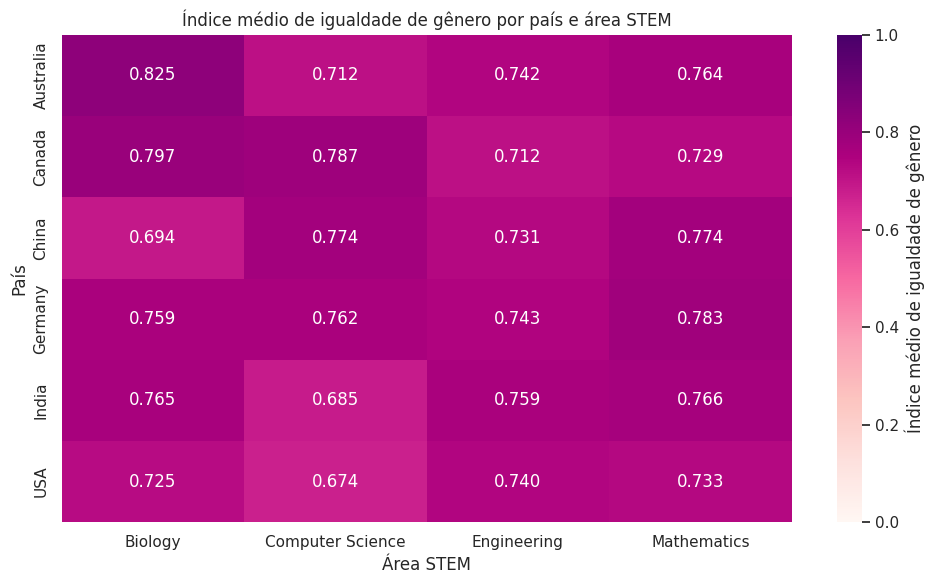

In [22]:
#Calcula o índice médio por país e área
medias_indice = (ds.groupby(["Country", "STEM Fields"])["Gender Gap Index"].mean().reset_index())

#Ordena as combinações do menor índice médio para o maior
menores_indices = medias_indice.sort_values("Gender Gap Index")

print("Combinações ordenadas do menor índice médio para o maior:")
print(menores_indices.round(3).to_string(index=False))

#Organiza os dados em uma matriz: países nas linhas e áreas nas colunas
tabela = medias_indice.pivot(
    index="Country",
    columns="STEM Fields",
    values="Gender Gap Index"
)

sns.set_style("white")
sns.set_context("notebook")

plt.figure(figsize=(10, 6))

#Cria o mapa de calor
sns.heatmap(
    data=tabela,
    annot=True,      # Mostra a média dentro de cada célula
    fmt=".3f",       # Exibe três casas decimais
    cmap="RdPu",     # Tons de rosa e roxo
    vmin=0,         # Valor mínimo da escala
    vmax=1,         # Valor máximo da escala
    cbar_kws={"label": "Índice médio de igualdade de gênero"}
)

plt.title("Índice médio de igualdade de gênero por país e área STEM")
plt.xlabel("Área STEM")
plt.ylabel("País")

plt.tight_layout()
plt.show()

4- Em qual país existe a maior diferença entre os percentuais médios de matrícula feminina nas quatro áreas STEM?

5- Qual área apresentou o maior crescimento do percentual médio de matrícula feminina entre 2000 e 2023?

6- Qual é a tendência do índice médio de igualdade de gênero ao longo dos anos em cada país?

7- Nos Estados Unidos, entre 2010 e 2023, qual é a tendência da matrícula feminina em Ciência da Computação e em quais anos a média ficou abaixo de 40%?

8- Qual é o índice médio de igualdade de gênero na área de Engenharia em cada país no ano de 2023?

9- Quais são os coeficientes de correlação entre o percentual de matrícula feminina, o percentual de conclusão feminina e o índice de igualdade de gênero?

10-  Como o percentual médio de matrícula feminina em Engenharia, Ciência da Computação, Matemática e Biologia se compara entre Estados Unidos, China e Índia no período de 2015 a 2023?